In [35]:
%matplotlib inline
from matplotlib import rcParams
import matplotlib.pyplot as plt

# Introduction to Ensemble Methods

Ensemble methods are techniques for obtaining better predictive performances by using multiple models.

To get an overview of the methods we are going to see today, you can watch this video of Machine learnia about Ensemble learning : https://www.youtube.com/watch?v=7C_YpudYtw8 (you don't need to understand everything before beginning the notebook ;)).

The following dataset comes from a bank which would like to know when a new client arrives if this client will subscribe to a long term deposit.

The bank will be considered as your client in the following parts.

---

**Feel free to create sklearn Pipelines for simplifying the following experiments** 

## Introducing and exploring the dataset

The dataset is located in `../data/bank-full.csv`. It has 17 columns, the target column or $ŷ$ is the column named `y`.

Columns summary  : 

| column name | simple description |
|-------------|------------------------|
| age | age |
| job | type of job |
| marital | marital status |
| education | education level |
| default | has credit in default? |
| balance | average yearly balance, in euros  |
| housing | has housing loan? |
| loan | has personal loan? |
| contact | contact communication |
| month | last contact month of year |
| day_of_week | last contact day of the week |
| duration |  last contact duration in seconds |
| campaign |  number of contacts performed during campaign for this client |
| pday | number of days that passed by after the client was last contacted from a previous campaign (-1 means client was not previously contacted) |
| previous | number of contacts performed before this campaign and for this client |
| poutcome | outcome of the previous marketing campaign |
| **output :** |  |
| y | has  the client subscribed a term deposit? |

Let's explore the dataset a bit using pandas.

While exploring the dataset it is recommended to create a list of categorical features

In [36]:
import pandas as pd

Create a dataframe with the dataset `../data/bank-full.csv`

In [37]:
# code here
dataset = pd.read_csv('../data/bank-full.csv', sep=";", encoding="utf-8")


dataset.info()
dataset.describe()


<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  str  
 2   marital    45211 non-null  str  
 3   education  45211 non-null  str  
 4   default    45211 non-null  str  
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  str  
 7   loan       45211 non-null  str  
 8   contact    45211 non-null  str  
 9   day        45211 non-null  int64
 10  month      45211 non-null  str  
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  str  
 16  y          45211 non-null  str  
dtypes: int64(7), str(10)
memory usage: 5.9 MB


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Describe the dataset informations

In [38]:
# code here
dataset.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Use histogramms to display the features' distribution

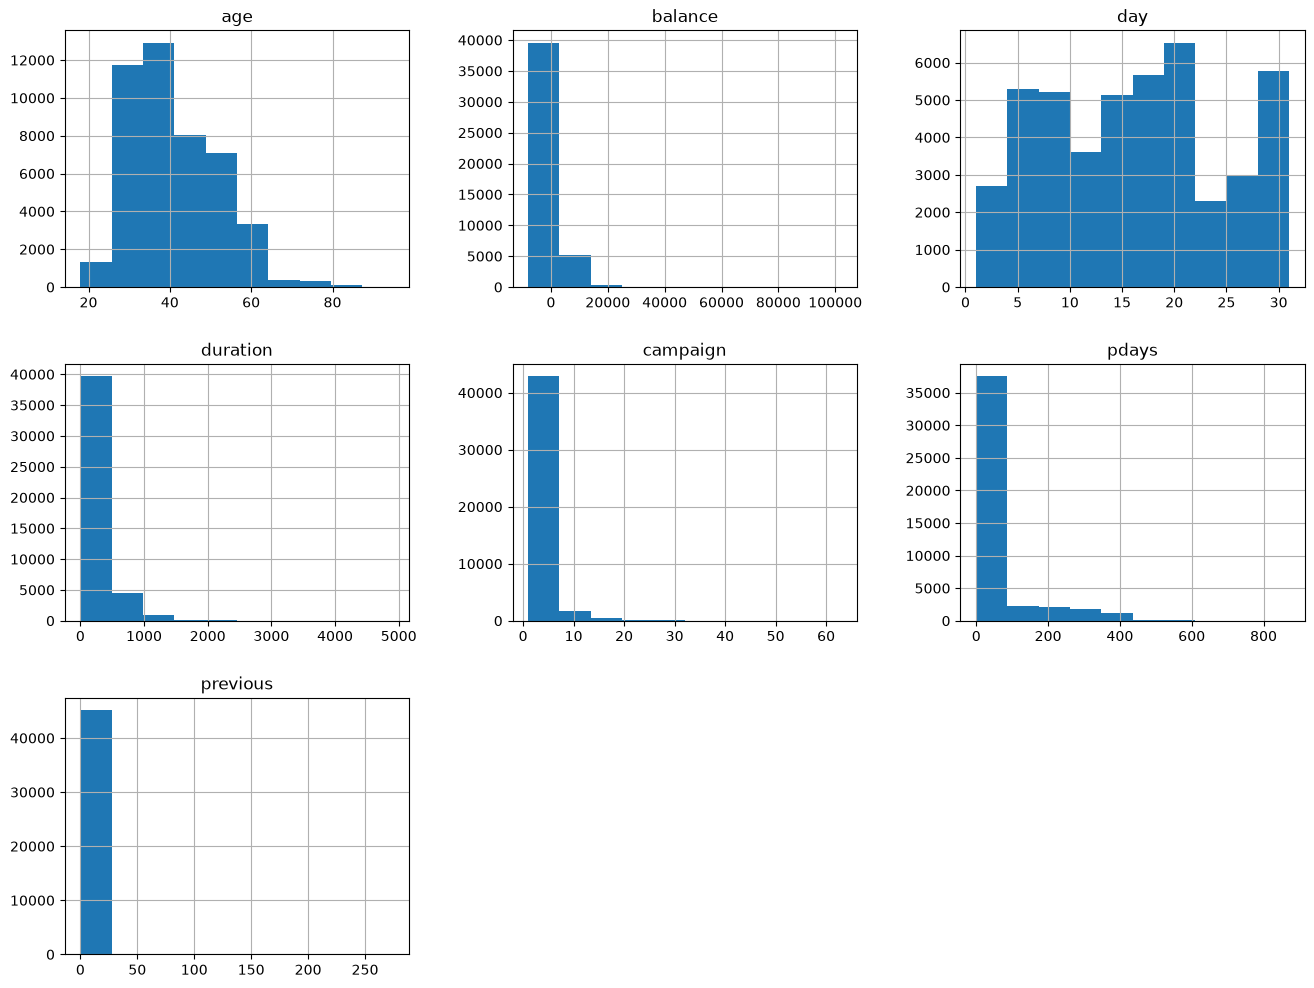

(45211, 17)


In [39]:
# code here
rcParams['figure.figsize'] = 16,12
plots = dataset.hist()
plt.show()

print(dataset.shape)

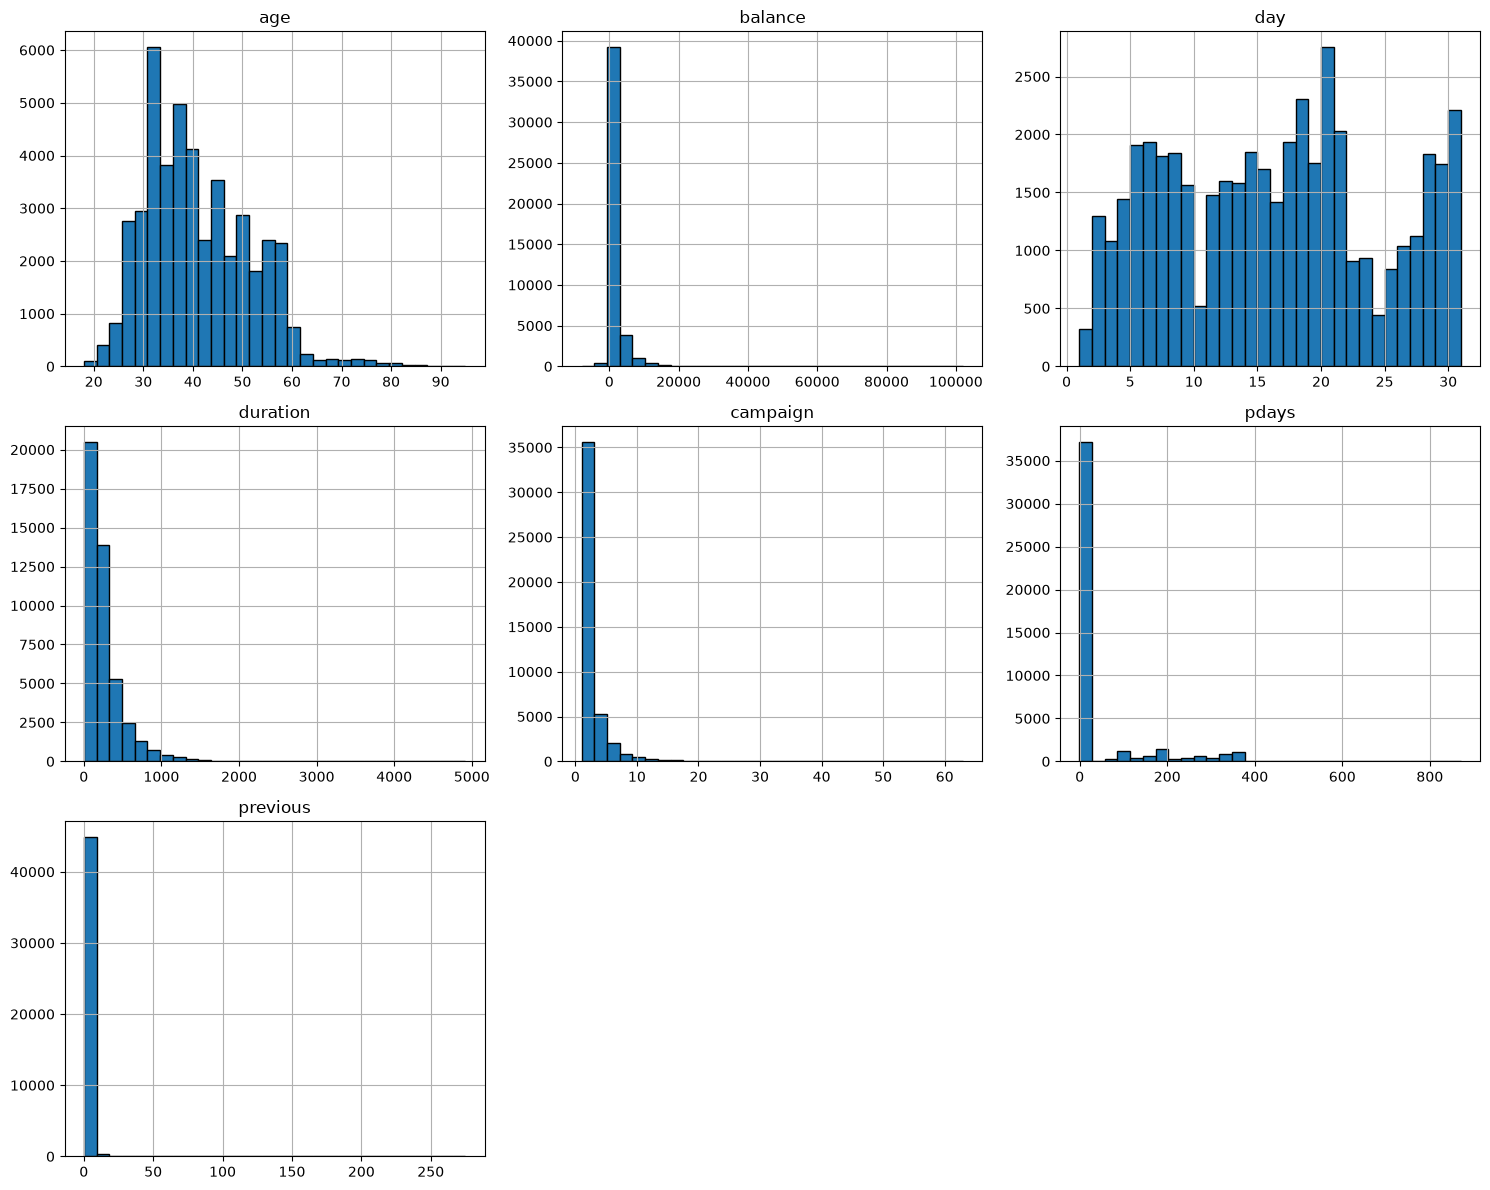

In [40]:
## El mismo histograma pero solo con columnas numericas

# Seleccionar columnas numéricas
numerical_features = dataset.select_dtypes(include=['int64', 'float64'])

# Mostrar histogramas
numerical_features.hist(figsize=(15, 12), bins=30, edgecolor='black')

plt.tight_layout()
plt.show()

Use heatmap to display the numerical features' correlation

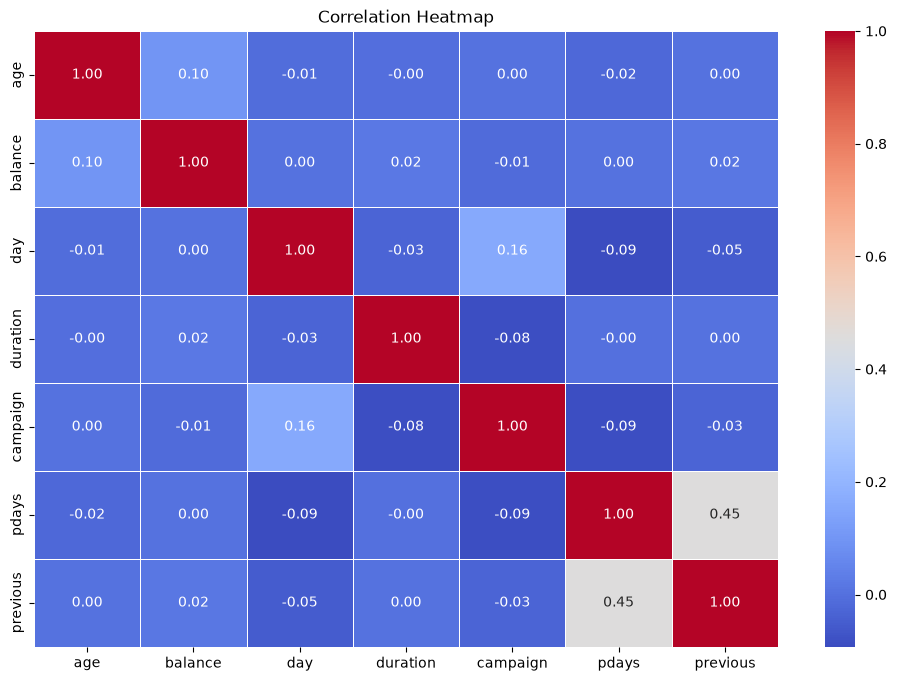

In [41]:
# code here
import seaborn as sns
## Mostrar la correlación mediante un Heatmap

# Calcular matriz de correlación
correlation_matrix = numerical_features.corr()

# Mostrar heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()


Hop hop hop!!! Not to fast!! Before processing data for machine learning, do you think that all the data are useful?  
As an expert, I tell you you should removed the duration column!!

Could you tell me why?

💡*think first, but if you have no idea double click here.*
<!-- When do your calls last the most? --> 

Index(['age', 'job', 'marital', 'education', 'default', 'balance', 'housing',
       'loan', 'contact', 'day', 'month', 'campaign', 'pdays', 'previous',
       'poutcome', 'y'],
      dtype='str')


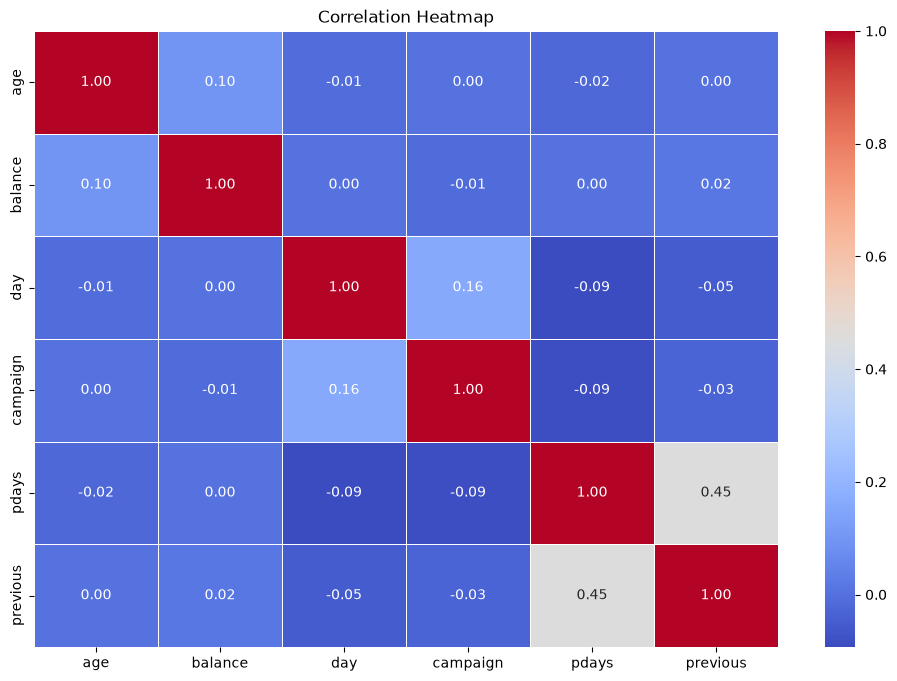

In [42]:
# remove duration column
""" 
    ¿Por qué debemos eliminar la columna duration?
    La columna duration representa la duración, en segundos, de la última llamada telefónica realizada al cliente.

    El problema es que esta variable introduce Data Leakage (fuga de información).

    Vamos a entenderlo.

    Imagina que queremos construir un modelo que prediga si un cliente contratará un depósito bancario (y):

        y = yes: el cliente contrata el producto.
        y = no: el cliente no lo contrata.

    Si utilizamos duration como característica para entrenar el modelo, estamos proporcionando información que no conocemos antes de realizar la llamada.

    ¿Por qué?

        Antes de llamar al cliente, no conocemos la duración de la conversación.
        La duración solo se conoce una vez que la llamada ha terminado.
        Por tanto, utilizar esta variable para predecir si el cliente contratará el producto supone utilizar información del futuro.

    Esto puede provocar que nuestro modelo obtenga resultados excelentes durante el entrenamiento y las pruebas, pero que no funcione correctamente en una situación real
"""

## Elimino la Columna Duracion del DataFrame
dataset = dataset.drop(columns=['duration'])


""" 
    La colonne duration représente la durée du dernier appel téléphonique avec le client, exprimée en secondes.
    Nous devons supprimer cette colonne car elle provoque un problème de fuite de données (Data Leakage).
    En effet, la durée de l'appel n'est connue qu'après la fin de la conversation. Or, notre objectif est de prédire 
    si un client va souscrire à un dépôt bancaire avant de le contacter.
    Utiliser cette variable dans notre modèle reviendrait donc à utiliser une information qui n'est pas disponible au moment de la prédiction.
    Cela pourrait donner des résultats artificiellement élevés lors de l'entraînement et de l'évaluation 
    du modèle, mais de mauvaises performances en conditions réelles.
    C'est pourquoi nous supprimons la colonne duration avant de commencer l'entraînement du modèle.
"""


print(dataset.columns)

## Re-creo correlación mediante un Heatmap

# Seleccionar columnas numéricas
numerical_features = dataset.select_dtypes(include=['int64', 'float64'])

# Calcular matriz de correlación
correlation_matrix = numerical_features.corr()

# Mostrar heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap')
plt.show()


The date is a strange type of data for machine learning. Think about it. Is the day? the month? the year that are important? Or the relative date for instance in the year?

If the phenomenon occurs seasonally, maybe it is better to look at the day of the year (on 365 days), if it monthly, maybe to look at the day in the month (on approximativally 30, 31 or other for bissextile year), etc... If more complex, well do the proper hypothesis and test it.

For our problem, we supposed it is better to look at the day of the year. Maybe it is a good hypothesis, maybe not. It is an hypothesis we want you to test. So in order to continue the preprocessing, the features `day` and `month` should be merged into one column named `dayoftheyear`. 

You can use pandas datetime tools or python **datetime** librairies for doing this preprocessing. To find the the day of year, look as *dayofyear* method from **datetime** library and examples such as https://pythonguides.com/extract-day-number-of-the-year-from-a-date-in-python/ or https://docs.lucee.org/reference/functions/dayofyear.html
(the default year used will be 1984)

In [43]:
#code here
# You can concatenate multiple Series containing string by just summing them.
# However, be sure each Serie contains string, in case use .astype(str)

""" 
¿Qué problema tenemos con las fechas?
    En tu dataset Bank Marketing tienes dos columnas relacionadas con la fecha:
        day: día del mes en el que se realizó el contacto.
        month: mes en el que se realizó el contacto.
    El problema es que los algoritmos de Machine Learning no interpretan necesariamente las fechas como lo hacemos las personas.
            Por ejemplo, imaginemos estos registros:
                                                    day	month
                                                    15	jan
                                                    15	feb
                                                    15	mar
                                                    15	apr

    Si utilizamos estas dos columnas por separado, el algoritmo puede aprender relaciones independientes entre el día y el mes.
    Sin embargo, quizá exista un patrón relacionado con el momento concreto del año en el que se realiza la campaña.
    Por ejemplo, las campañas de marketing podrían tener mejores resultados en determinadas épocas del año.
    Por eso, la consigna propone combinar ambas columnas en una sola característica: dayoftheyear.
¿Qué significa dayoftheyear?
    Significa transformar una fecha en un número que representa el día del año.
    Por ejemplo, utilizando el año 1984 (año bisiesto, como indica la consigna):
                                            Fecha	dayoftheyear
                                                01/01/1984	1
                                                15/01/1984	15
                                                01/02/1984	32
                                                15/02/1984	46
                                                01/03/1984	61
                                                31/12/1984	366
        De esta manera, conseguimos representar el momento del año mediante una única variable numérica.
¿Qué ventaja tiene?
    El algoritmo puede identificar patrones temporales sin tener que interpretar dos variables independientes.
    Por ejemplo, puede detectar que los contactos realizados alrededor del día 150 del año tienen un comportamiento diferente de los realizados alrededor del día 300
"""

import datetime
dayoftheyear = None
dataset['dayoftheyear'] = dayoftheyear

dataset.describe()

dataset.info()

# Concatenar las columnas day y month con el año 1984
dates = (
    dataset['day'].astype(str) + '-' +
    dataset['month'].astype(str) + '-1984'
)

# Convertir las fechas y extraer el día del año
dayoftheyear = pd.to_datetime(
    dates,
    format='%d-%b-%Y'
).dt.dayofyear

# Añadir la nueva columna
dataset['dayoftheyear'] = dayoftheyear

## Compruebo el Resultado
dataset[['day', 'month', 'dayoftheyear']].head(10)

## Eliminar las columnas day y month "Porque ya no son necesarias Dado que se creo la Columna: (dayoftheyear) que contiene el numero que representa el Dia en el Anio"
dataset = dataset.drop(columns=['day', 'month'])

## Verifico la estructura Final
print("Verifico la estructura Final: \n")
dataset.info()

dataset.describe()



<class 'pandas.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age           45211 non-null  int64 
 1   job           45211 non-null  str   
 2   marital       45211 non-null  str   
 3   education     45211 non-null  str   
 4   default       45211 non-null  str   
 5   balance       45211 non-null  int64 
 6   housing       45211 non-null  str   
 7   loan          45211 non-null  str   
 8   contact       45211 non-null  str   
 9   day           45211 non-null  int64 
 10  month         45211 non-null  str   
 11  campaign      45211 non-null  int64 
 12  pdays         45211 non-null  int64 
 13  previous      45211 non-null  int64 
 14  poutcome      45211 non-null  str   
 15  y             45211 non-null  str   
 16  dayoftheyear  0 non-null      object
dtypes: int64(6), object(1), str(10)
memory usage: 5.9+ MB
Verifico la estructura Final: 

<class 'panda

/tmp/ipykernel_35310/4079878147.py:56: Pandas4Warning: Series.dt.dayofyear is deprecated and will be removed in a future version. Use Series.dt.day_of_year instead.
  ).dt.dayofyear


,age,balance,campaign,pdays,previous,dayoftheyear
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,2.763841,40.197828,0.580323,172.109044
std,10.618762,3044.765829,3.098021,100.128746,2.303441,74.763073
min,18.000000,-8019.000000,1.000000,-1.000000,0.000000,6.000000
25%,33.000000,72.000000,1.000000,-1.000000,0.000000,130.000000
50%,39.000000,448.000000,2.000000,-1.000000,0.000000,156.000000
75%,48.000000,1428.000000,3.000000,-1.000000,0.000000,218.000000
max,95.000000,102127.000000,63.000000,871.000000,275.000000,366.000000


We cannot treat the same way categories with numerical features. So let's make two different lists and different treatments. 

Now sort the features into categorical and numerical features

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'poutcome', 'y']
Numerical features: ['age', 'balance', 'campaign', 'pdays', 'previous', 'dayoftheyear']
age             int64
job               str
marital           str
education         str
default           str
balance         int64
housing           str
loan              str
contact           str
campaign        int64
pdays           int64
previous        int64
poutcome          str
y                 str
dayoftheyear    int32
dtype: object

 Equilibrio entre clientes que contratan y clientes que no contratan.: 


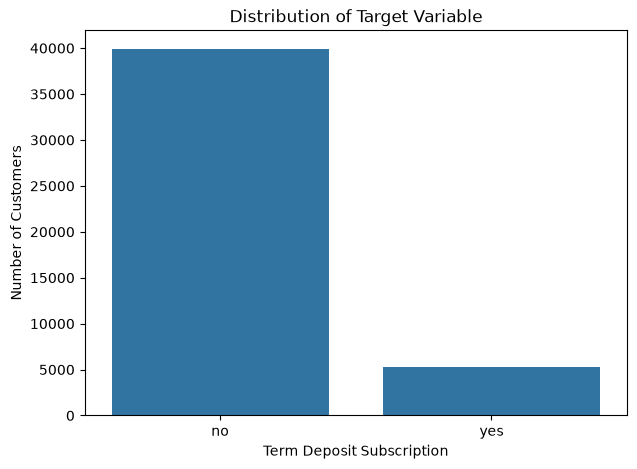

In [ ]:
categorical_features = [] # to be completed
numerical_features = [] # to be completed

## Método dinámico utilizando Pandas 
# Identify categorical features (identifica columnas de texto y categóricas.)
categorical_features = dataset.select_dtypes(include=['object', 'str', 'category']).columns.tolist()

# Identify numerical features (identifica columnas numéricas.)
numerical_features = dataset.select_dtypes(include=['number']).columns.tolist()
""" 
¿Qué esta haciendo?
    select_dtypes(): selecciona las columnas según su tipo de dato.
    include=['object', 'category']: identifica columnas de texto y categóricas.
    include=['int64', 'float64']: identifica columnas numéricas.
    .columns: devuelve los nombres de las columnas.
    .tolist(): transforma el resultado en una lista de Python.
Importante: esta clasificación se basa en el significado de las variables, no exclusivamente en su tipo de dato.
"""


print("Categorical features:", categorical_features)
print("Numerical features:", numerical_features)


print(dataset.dtypes)

## **** Distribución de la variable objetivo
## Debemos comprobar si tenemos un desequilibrio entre clientes que contratan y clientes que no contratan.

print("\n Equilibrio entre clientes que contratan y clientes que no contratan.: ")
dataset['y'].value_counts(normalize=True) * 100

""" 
    una característica fundamental de nuestro problema: tenemos un dataset con clases desbalanceadas (Class Imbalance).
¿Qué problema representa esto?
    Estamos ante un caso de Class Imbalance (desequilibrio de clases).
        Tenemos:
            Clase mayoritaria: no (88.30 %).
            Clase minoritaria: yes (11.70 %).
¿Por qué es importante?
Imagina que construimos un modelo que siempre predice:
python
                            y = 'no'
¿Qué accuracy obtendríamos?
                            ¡Un 88.30 %!
Sin embargo, nuestro modelo sería completamente inútil para identificar a los clientes que realmente podrían contratar el depósito.

Conclusión del análisis de la variable objetivo:
El dataset presenta un desequilibrio significativo entre las clases de la variable objetivo y. Aproximadamente el 88,30 % 
de los clientes no ha contratado un depósito a plazo, mientras que solamente el 11,70 % sí lo ha contratado.
Este desequilibrio deberá tenerse en cuenta durante la construcción y evaluación de los modelos Ensemble. 
En particular, será necesario utilizar métricas como Precision, Recall, F1-score y PR-AUC, evitando depender exclusivamente de Accuracy.

"""


plt.figure(figsize=(7, 5))

sns.countplot(data=dataset, x='y')

plt.title('Distribution of Target Variable')
plt.xlabel('Term Deposit Subscription')
plt.ylabel('Number of Customers')

plt.show()


After a first exploration, categorical/ordinal features (8 columns) need to be encoded in order to become a valid input for the modeling phase. ML manipulates figures, not string, not category by itself.

Look at the encoder to *encode* your *categorical data*. The different encoders can be found [here](https://scikit-learn.org/stable/api/sklearn.preprocessing.html).

(You can also use the function `gethg_dummies` of pandas for categorical features)

In [68]:
# Create the X and y DataFrames resample the dataframes if necessary
""" 
Tipo de variable	    Columnas	                                                                    Transformación
Categóricas             nominales	job, marital, default, housing, loan, contact, poutcome	            OneHotEncoder
Categórica              ordinal	education	                                                            OrdinalEncoder
Numéricas	            age, balance, campaign, pdays, previous, dayoftheyear	                        Passthrough inicialmente
Target	                y	                                                                            Codificación binaria
"""

import numpy as np

from sklearn.model_selection import train_test_split


## Preparación de los datos para los modelos Ensemble (Data Preprocessing).

# Define target variable
target = 'y'

# Create X (features)
X = dataset[categorical_features + numerical_features]

# Create y (target)
y = dataset[target].map({'no': 0, 'yes': 1})

print("X shape:", X.shape) # X: contiene las características de nuestros clientes.
print("y shape:", y.shape) # y: contiene la respuesta que queremos predecir.



# train_test split
# X_train, X_test, y_train, y_test = None

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
""" 
stratify=y mantiene aproximadamente estas proporciones en los conjuntos de entrenamiento y prueba.
"""

## Compruebo las dimensiones
print("Compruebo las dimensiones: ")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)


X shape: (45211, 15)
y shape: (45211,)
Compruebo las dimensiones: 
X_train: (36168, 15)
X_test: (9043, 15)
y_train: (36168,)
y_test: (9043,)


In [69]:
# import and create the appropriate transformers 
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder

""" 
        OneHotEncoder para las 8 variables categóricas.
        passthrough para conservar las 6 variables numéricas.
"""

# Categorical pipeline
categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Numerical pipeline
numerical_pipeline = Pipeline([
    ('passthrough', 'passthrough')
])

# Column Transformer
preprocessor = ColumnTransformer(
    transformers=[
        ('categorical', categorical_pipeline, categorical_features),
        ('numerical', numerical_pipeline, numerical_features)
    ]
)

## Ajustar el preprocessor
# Fit and transform training data
X_train_encoded = preprocessor.fit_transform(X_train) # aprende las categorías y transforma los datos de entrenamiento.

# Transform testing data
X_test_encoded = preprocessor.transform(X_test) # aplica las mismas transformaciones al conjunto de test.

print("X_train_encoded:", X_train_encoded.shape)
print("X_test_encoded:", X_test_encoded.shape)

print("Original X_train:", X_train.shape)
print("Encoded X_train:", X_train_encoded.shape)

print("Original X_test:", X_test.shape)
print("Encoded X_test:", X_test_encoded.shape)

feature_names = preprocessor.get_feature_names_out()

print(feature_names)



X_train_encoded: (36168, 40)
X_test_encoded: (9043, 40)
Original X_train: (36168, 15)
Encoded X_train: (36168, 40)
Original X_test: (9043, 15)
Encoded X_test: (9043, 40)
['categorical__job_admin.' 'categorical__job_blue-collar'
 'categorical__job_entrepreneur' 'categorical__job_housemaid'
 'categorical__job_management' 'categorical__job_retired'
 'categorical__job_self-employed' 'categorical__job_services'
 'categorical__job_student' 'categorical__job_technician'
 'categorical__job_unemployed' 'categorical__job_unknown'
 'categorical__marital_divorced' 'categorical__marital_married'
 'categorical__marital_single' 'categorical__education_primary'
 'categorical__education_secondary' 'categorical__education_tertiary'
 'categorical__education_unknown' 'categorical__default_no'
 'categorical__default_yes' 'categorical__housing_no'
 'categorical__housing_yes' 'categorical__loan_no' 'categorical__loan_yes'
 'categorical__contact_cellular' 'categorical__contact_telephone'
 'categorical__contac

At the end of this part, two dataframes are created :

- `X` containing the features (or the matrix $X$)
- `y` containing the label (or $ŷ$)

Well done! The data is now ready to be splitted into sets and used to train models!

## Modelling phase

The client needs two features :

1. A model, which can be updated without performance loss. In other word, it means a pipeline easy to use and evaluate.
2. A model, that performs well.

### Dummy Classifier

It is always a good idea to begin with a dummy model as a baseline

In [71]:
from sklearn.dummy import DummyClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import f1_score, accuracy_score

# Create Dummy Classifier Pipeline
dummy_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DummyClassifier(strategy='most_frequent'))
])

""" 
    ¿Qué significa strategy='most_frequent'?
    El clasificador siempre predice la clase más frecuente del conjunto de entrenamiento.
"""

# Train Dummy Classifier
dummy_pipeline.fit(X_train, y_train)


# Predictions
y_pred_dummy = dummy_pipeline.predict(X_test)


# Calculate metrics
dummy_f1 = f1_score(
    y_test,
    y_pred_dummy,
    pos_label=1,
    zero_division=0
)

""" 
    ¿Por qué utilizamos pos_label='yes'?
    Porque nuestra clase positiva es yes: queremos identificar a los clientes que contrataron el depósito.
    zero_division=0 evita warnings cuando no existen predicciones positivas.
"""

dummy_accuracy = accuracy_score(
    y_test,
    y_pred_dummy
)

# Display results
print("Dummy Classifier Results")
print("------------------------")
print(f"F1-score: {dummy_f1:.4f}")
print(f"Accuracy: {dummy_accuracy:.4f}")




# Code here to get dummy classifier F1score and accuracy

Dummy Classifier Results
------------------------
F1-score: 0.0000
Accuracy: 0.8830


### Simple Decision Tree

We will experiment both feature by doing the two following steps.

* Training the Decision Tree model with various splits of the dataset (change the `seed` parameter of the `train_test_split` function for obtaining the second dataset)
* The decision tree `max_depth` will be fixed at 3 first

if you need more info you can take a look at the [sklearn decision tree doc](https://scikit-learn.org/stable/modules/tree.html).

In [ ]:
# Decision tree model creation and tree visualization
from sklearn.tree import DecisionTreeClassifier


# Decision Tree Pipeline
tree_pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(
        max_depth=3,
        random_state=42
    ))
])

X_train_42, X_test_42, y_train_42, y_test_42 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Train model
tree_pipeline.fit(X_train_42, y_train_42)

# Predictions
y_pred_42 = tree_pipeline.predict(X_test_42)

accuracy_42 = accuracy_score(y_test_42, y_pred_42)

f1_42 = f1_score(
    y_test_42,
    y_pred_42,
    pos_label=1,
    zero_division=0
)

print("Decision Tree - Random State 42")
print(f"Accuracy: {accuracy_42:.4f}")
print(f"F1-score: {f1_42:.4f}")

print("\n")


X_train_21, X_test_21, y_train_21, y_test_21 = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=21,
    stratify=y
)

## Entreno nuevamente el modelo

# Train model with second dataset
tree_pipeline.fit(X_train_21, y_train_21)

# Predictions
y_pred_21 = tree_pipeline.predict(X_test_21)

## Calculo las nuevas metricas
accuracy_21 = accuracy_score(y_test_21, y_pred_21)

f1_21 = f1_score(
    y_test_21,
    y_pred_21,
    pos_label=1,
    zero_division=0
)

print("Decision Tree - Random State 21")
print(f"Accuracy: {accuracy_21:.4f}")
print(f"F1-score: {f1_21:.4f}")

## Creo un nuevo DataFrame para con la informacion de la comparacion:
results = pd.DataFrame({
    'Model': [
        'Decision Tree (seed=42)',
        'Decision Tree (seed=21)'
    ],
    'Accuracy': [
        accuracy_42,
        accuracy_21
    ],
    'F1-score': [
        f1_42,
        f1_21
    ]
})

print(results) 


## Genero la visualizacion del Arbol de decision
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# Get transformed feature names
feature_names = tree_pipeline.named_steps[
    'preprocessor'
].get_feature_names_out()

# Visualize decision tree
plt.figure(figsize=(24, 12))

plot_tree(
    tree_pipeline.named_steps['classifier'],
    feature_names=feature_names,
    class_names=['no', 'yes'],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.title('Decision Tree Classifier - Max Depth 3')
plt.show()

ValueError: pos_label=yes is not a valid label. It should be one of [0 1]

Now, a first model has been created, change the random seed for the train/test split, and create another tree.

This tree should be created with the same hyperparameters than above. 

In [ ]:
# create a new train and test dataset with a different seed

In [ ]:
# Second tree creation

What can you tell about the two trees?

*answer here*

Normally, before creating a model, one or more evaluation metrics should be chosen depending on the client problem.

* Choose different metrics that seem relevant to this problem (see previous lesson on Classification)

* Prepare a scoring list for these metrics.

* Use the cross-validation method to measure these metrics (if you need see : [cross validation sklearn](https://scikit-learn.org/stable/modules/cross_validation.html)). 

*Hint:*  the `cross_validate` method allows you to pass a metric list as parameter (see [doc here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html) ).

In [ ]:
# Test if the target is balanced

In [ ]:
# Cross validation on Decision trees
from sklearn.model_selection import cross_val_score
metrics = []

Now process the output of your cross-validation in order to know the diversity in performances and the average performance

In [ ]:
# BONUS: performance plot 
# Create a bar plot showing the mean and the standard deviation for each metric

Now choose a single metric to perform a grid search on the `max_depth` of the tree.

In [ ]:
# Grid search

Now retrain the model with the selected hyperparameters on your whole train set and evaluate the selected model on the test set :

In [ ]:
# Test metrics

What are your observation?  
By looking at the metric results, what is strange? Or at the opposite, obvious?

From theses observations, what are your conclusions?  
In the next sessions, we will look at ensembling to improve performances. But what should you be suspicious? What are the potential risks you identified?  

Propose something, continue to the next section and change your conclusions if you need.

### Introducing Ensemble Learning with Bagging models.

Let's train multiple classifiers in parallel in a bootstraping approach! 

Bagging stands for ***Boostrap AGGregatING***.

The following [post](https://blog.octo.com/les-methodes-ensemblistes-pour-algorithmes-de-machine-learning/) will give you an overview of these methods and their advantages and drawbacks

**The train test split using a seed equals to 42 will be used in the following part**

In [ ]:
# train_test split (you can copy paste the previously declared cell)
# X_train, X_test, y_train, y_test = None

#### Using Random Forest

The concept of random forest is explained in this [post](https://medium.com/analytics-vidhya/understanding-the-random-forest-algorithm-79b87bdde79a).

Now the best parameters of the previous classifier will be used in a using a bagging classifier
[sklearn : Random Forest Doc](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html?highlight=random%20forest#sklearn.ensemble.RandomForestClassifier)

We will use grid search on the `n_estimators` and `max_depth` parameters. 

In [ ]:
# gridsearch for the Random Forest classifier
#

How much estimators should we use for obtaining an optimal result? (in terms of time and performance)

*answer here*

Now retrain the model with the selected hyperparameters on your whole train set and evaluate the selected model on the test set :

In [ ]:
# Test metrics

#### Other Random Forest effect

The random forest model can attribute an importance value to features, [explanations here](https://towardsdatascience.com/explaining-feature-importance-by-example-of-a-random-forest-d9166011959e)

Let's train another random forest and display an histogramm with it :

In [ ]:
# display features' importance => use the RandomForest Object

What is the most important feature?

*Answer here*

A lot of features have low importance and probably add noise which reduce the performance of the classifier, do a feature selection by recursive elemination to automatically select the subset of features that gives you the best model predictions.

You can have a look at : 

https://scikit-learn.org/stable/modules/feature_selection.html

https://scikit-learn.org/stable/auto_examples/feature_selection/plot_rfe_with_cross_validation.html#sphx-glr-auto-examples-feature-selection-plot-rfe-with-cross-validation-py

In [ ]:
# Feature selection with recursive elimination
# Do another grid search on your model with the subset of selected features

We removed the duration feature in our dataset

Read this feature description on the dataset description ([here on data.world](https://data.world/uci/bank-marketing) or [here on kaggle](https://www.kaggle.com/janiobachmann/bank-marketing-dataset)).

How would the previously trained models perform with this feature?

*Answer here*

### Continue Ensemble Learning with boosting techniques

Bagging permits to average the results of separated models, whereas the boosting technique trains a classifier and optimizes it in function of its error.

Some information about boosting techniques are on the [sklearn documentation](https://scikit-learn.org/stable/modules/ensemble.html#gradient-tree-boosting) but a commonly used library for these techniques is [XGBoost](https://xgboost.readthedocs.io/en/latest/index.html) there are some compatibilities with the sklearn methods (gridsearch, cross validation,...)

- install the `xgboost` package

*Read the articles in resources for a complete explanation.*

In this part a classifier will be trained and evaluated.

In [ ]:
# use the same split and seed than you used before
# normally, you have nothing to code here :D 

*Hint:* An example for integrating `XGBoost` with  the `sklearn` tools is available [here](https://medium.com/@juniormiranda_23768/ensemble-methods-tuning-a-xgboost-model-with-scikit-learn-54ff669f988a)

In [ ]:
import xgboost as xgb

Let's build a new model than before with a grid search on the `n_estimators` and `max_depth` parameters.

In [ ]:
# model building and evaluation

In [ ]:
# gridsearch 

Now retrain the model with the selected hyperparameters on your whole train set and evaluate the selected model on the test set :

In [ ]:
# Test metrics

In [ ]:
# performance curves

## Let's Conclude

Report your test set metrics for the three methods here

In [ ]:
# Decision Tree on test set

In [ ]:
# Random forest on test set

In [ ]:
# XGBoost on test set

What do you notice? What are you real conclusion about the dataset? What should you tell the client about the dataset and his problem?

*answer here*

- Write your memo about bagging and boosting method in a cell below.
- Which model would you choose for the bank, and why? Which precautions?

you can add your models result visualization in this cell if it helps you explaining your conclusions.

                                 `write memo here`

## To go further

### Build a customized bagging classifier (Optional) 

- Use a different classification model you have seen until now and build a new classifier based on the [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html#sklearn.ensemble.BaggingClassifier) to create and train an new model.
- Use differents classification models and use the [VotingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html#sklearn.ensemble.VotingClassifier) to create and train a new model.

In [ ]:
# Write your code here

## Rebalance the data if you haven't done it yet

Before going through the modelling phase, let's see the label distribution :

Use the `value_counts` function and the appropriate visualization for displaying the label distribution

In [ ]:
# code here

What do you notice?

*answer here*

The easiest way to rebalance your data is to add the `class_weight='balanced'` parameter to your scikit learn model. The `class_weight` parameter is available in most scikit-learn models, for example look at the Decision Trees doc :
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

(There are other techniques for rebalancing the data [here](https://blog.octo.com/donnees-desequilibrees-que-faire/), [here](https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/) and [here](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedShuffleSplit.html) ).

Rebalance the data with the `class_weight` parameter, and you'll have much better f1 and Average Precision metrics.

In [ ]:
# code here